# PCA analysis
Notebook with code for the PCA analysis using the main features:
- size
- solubility
- lipophilicity
- flexibility
- saturation
- polarity

## Imports

In [1]:
from amp import load, work_in_outputs
work_in_outputs("03_pca")
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['svg.fonttype'] = 'none'

import numpy as np
from sklearn.decomposition import PCA


In [2]:
df_features = load("molecular_features")

In [3]:
# list of features used fo the analysis
features = ['MolWt','Mean Log P','TPSA','NumRotatableBonds','FractionCSP3','Mean Log S']

## Correlation Matrix

<Axes: >

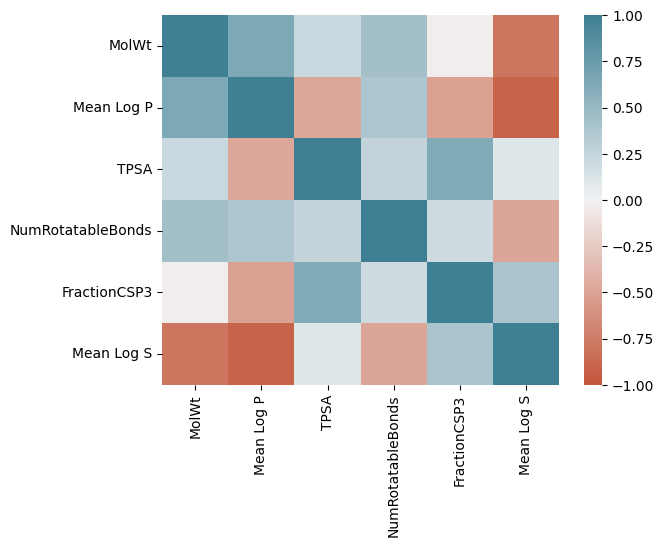

In [4]:
# Plot correlation matrix

sns.heatmap(df_features[features].corr(), vmin=-1, vmax=1,
            cmap=sns.diverging_palette(20, 220, as_cmap=True))

Text(0.5, 1.0, 'Spearman')

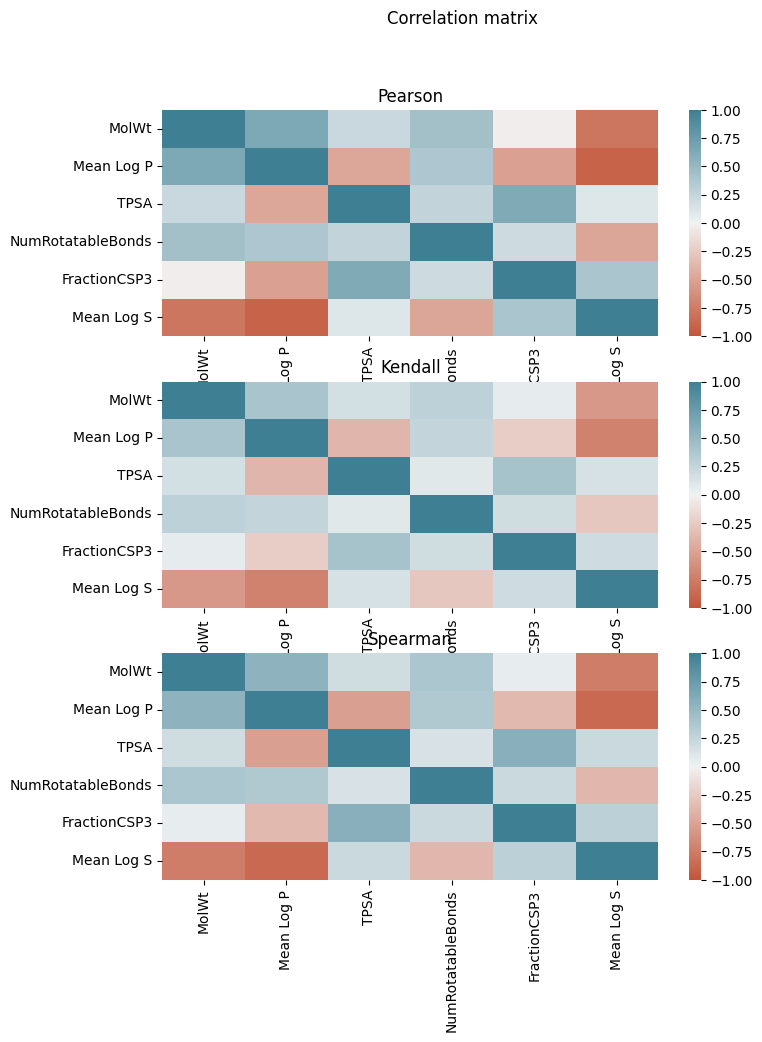

In [5]:
# Compare different correlation matrix

fig, axes = plt.subplots(3, 1, figsize=(8, 10))
fig.suptitle('Correlation matrix')

# Pearson
sns.heatmap(ax=axes[0], data=df_features[features].corr(method='pearson'), vmin=-1, vmax=1,
            cmap=sns.diverging_palette(20, 220, as_cmap=True))
axes[0].set_title('Pearson')

# Kendall
sns.heatmap(ax=axes[1], data=df_features[features].corr(method='kendall'), vmin=-1, vmax=1,
            cmap=sns.diverging_palette(20, 220, as_cmap=True))
axes[1].set_title('Kendall')

# Sspearman
sns.heatmap(ax=axes[2], data=df_features[features].corr(method='spearman'), vmin=-1, vmax=1,
            cmap=sns.diverging_palette(20, 220, as_cmap=True))
axes[2].set_title('Spearman')

## PCA without scaler

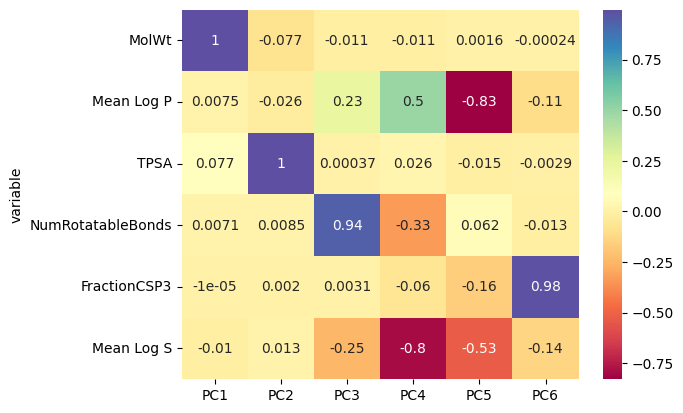

In [6]:
pca_ws = PCA().fit(df_features[features])
num_pc = pca_ws.n_features_in_
loadings = pca_ws.components_
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = df_features[features].columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()

## PCA with Standard Scaler

### Test Normality

In [7]:
from scipy.stats import shapiro

for column in df_features[features]:
    print(column)
    stat, p = shapiro(df_features[column])
    print('stat=%.3f, p=%.3f' % (stat,p))
    if p > 0.05:
	    print('Probably Gaussian')
    else:
	    print('Probably not Gaussian')

MolWt
stat=0.853, p=0.000
Probably not Gaussian
Mean Log P
stat=0.943, p=0.000
Probably not Gaussian
TPSA
stat=0.965, p=0.000
Probably not Gaussian
NumRotatableBonds
stat=0.886, p=0.000
Probably not Gaussian
FractionCSP3
stat=0.955, p=0.000
Probably not Gaussian
Mean Log S
stat=0.911, p=0.000
Probably not Gaussian


### Scalling

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [9]:
df_st =  StandardScaler().fit_transform(df_features[features])
print(df_features[features].head(5))
print(pd.DataFrame(df_st, columns=df_features[features].columns).head(5))

     MolWt  Mean Log P    TPSA  NumRotatableBonds  FractionCSP3  Mean Log S
0  754.785    6.313150  217.35               14.0      0.333333      -10.98
1  726.731    5.433450  239.35               12.0      0.300000      -11.22
2  386.400    2.995367  124.29                6.0      0.333333       -5.51
3  372.373    2.581350  135.29                5.0      0.300000       -5.63
4  354.358    3.091300  115.06                4.0      0.200000       -5.81
      MolWt  Mean Log P      TPSA  NumRotatableBonds  FractionCSP3  Mean Log S
0  2.053287    1.676826  2.291924           4.260846      0.751422   -2.823763
1  1.875739    1.211742  2.737336           3.475994      0.532423   -2.942047
2 -0.278137   -0.077233  0.407832           1.121438      0.751422   -0.127878
3 -0.366911   -0.296117  0.630538           0.729013      0.532423   -0.187020
4 -0.480924   -0.026515  0.220961           0.336587     -0.124573   -0.275733


### Loadings analysis

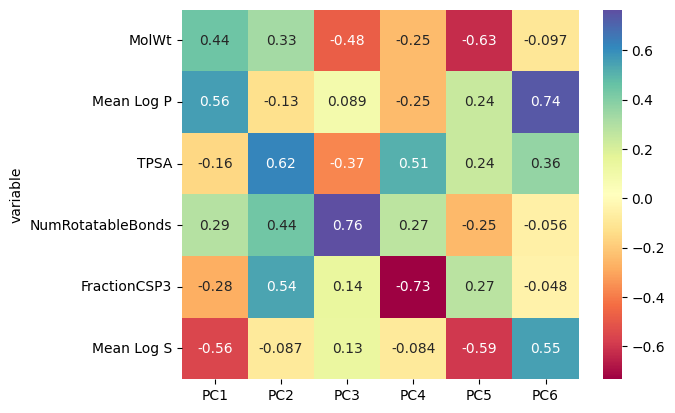

In [10]:
pca_st = PCA().fit(df_st)
loadings = pca_st .components_
num_pc = pca_st .n_features_in_
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = df_features[features].columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()

### Number of components

In [11]:
print(np.array_str(pca_st.explained_variance_, precision=3))
print(np.array_str(pca_st.explained_variance_ratio_, precision=3))

[3.031 1.935 0.595 0.358 0.097 0.009]
[0.503 0.321 0.099 0.059 0.016 0.001]


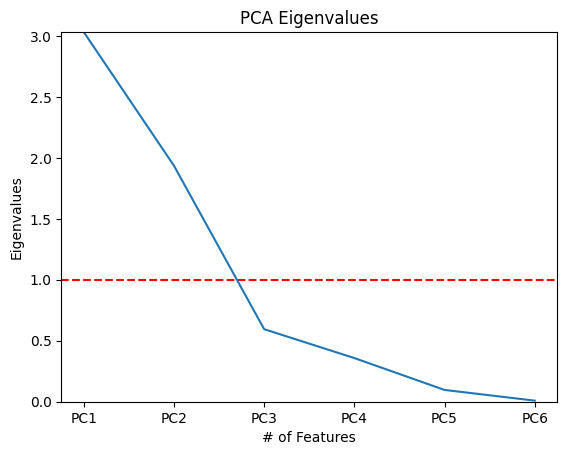

In [12]:
plt.ylabel('Eigenvalues')
plt.xlabel('# of Features')
plt.title('PCA Eigenvalues')
plt.ylim(0,max(pca_st.explained_variance_))
plt.style.context('seaborn-v0_8-whitegrid')
plt.axhline(y=1, color='r', linestyle='--')
plt.plot(pc_list, pca_st.explained_variance_)
plt.show()

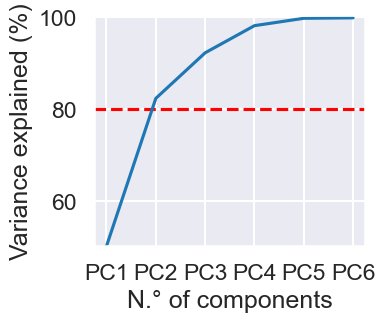

<Figure size 640x480 with 0 Axes>

In [13]:
sns.set_style('darkgrid')
sns.set_context("talk")

variance = pca_st.explained_variance_ratio_ #calculate variance ratios
var = np.cumsum(np.round(pca_st.explained_variance_ratio_,decimals=3)*100)

f, ax = plt.subplots(figsize=(3.5, 3))
plt.ylabel('Variance explained (%)')
ax.set_xlabel("N.° of components")
plt.ylim(min(var),100.5)
plt.axhline(y=80, color='r', linestyle='--')
plt.plot(pc_list,var)
plt.show()

plt.savefig('plots/scatter_scree-plot.svg')


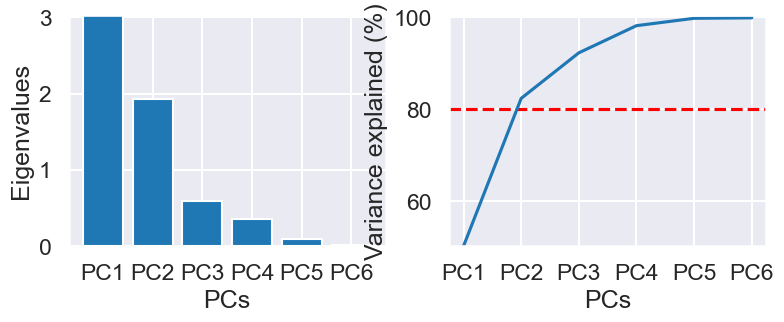

In [14]:
sns.set_style('darkgrid')
sns.set_context("talk")
f, ax = plt.subplots(1,2,figsize=(9, 3))

ax[0].set(xlabel='PCs', ylabel='Eigenvalues',
    ylim = [0,max(pca_st.explained_variance_)],yticks=[0,1,2,3])
#ax[0].axhline(y=1, color='r', linestyle='--')
ax[0].bar(x=pc_list, height=pca_st.explained_variance_)

ax[1].set(xlabel='PCs', ylabel='Variance explained (%)', ylim = [min(var),100.5])
ax[1].axhline(y=80, color='r', linestyle='--')
ax[1].plot(pc_list,var)

plt.savefig('plots/subplot_scree-plots.svg')

[Text(0.5, 0, '# of Feature'),
 Text(0, 0.5, '% Variance Explained'),
 (50.3, 100.5)]

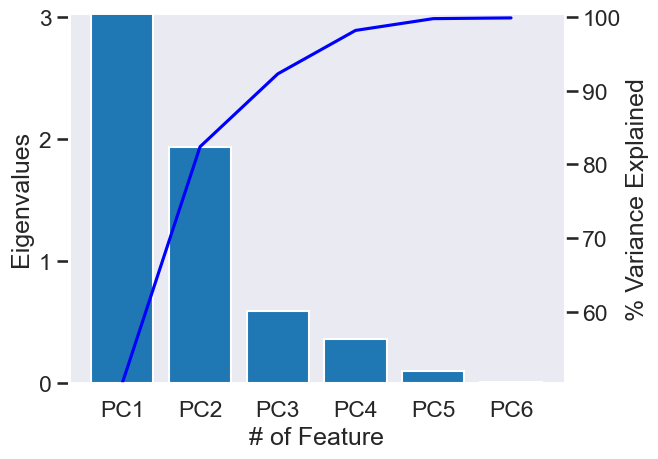

In [15]:
sns.set_style('dark')
sns.set_context("talk")

fig, ax1 = plt.subplots()

ax2 = ax1.twinx()
ax1.bar(x= pc_list, height= pca_st.explained_variance_)
ax2.plot(pc_list,var, 'b-')


ax1.set(xlabel='# of Feature', ylabel='Eigenvalues',
    ylim = [0,max(pca_st.explained_variance_)],yticks=[0,1,2,3])

ax2.set(xlabel='# of Feature', ylabel='% Variance Explained', ylim = [min(var),100.5])


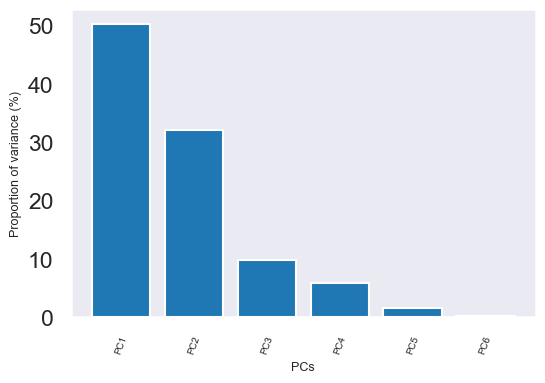

In [16]:
# get scree plot (for scree or elbow test)
from bioinfokit.visuz import cluster
cluster.screeplot(obj=[pc_list, pca_st.explained_variance_ratio_],show=True)

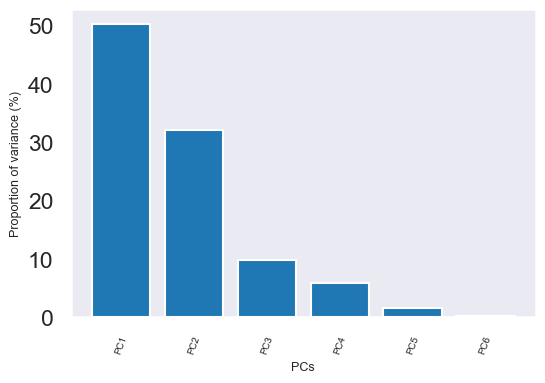

In [17]:
a = cluster.screeplot(obj=[pc_list, pca_st.explained_variance_ratio_],show=True)


## PCA with MinMax scaler

In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

### Scalling

In [19]:
df_mm =  MinMaxScaler().fit_transform(df_features[features])
print(df_features[features].head(5))
print(pd.DataFrame(df_mm, columns=df_features[features].columns).head(5))

     MolWt  Mean Log P    TPSA  NumRotatableBonds  FractionCSP3  Mean Log S
0  754.785    6.313150  217.35               14.0      0.333333      -10.98
1  726.731    5.433450  239.35               12.0      0.300000      -11.22
2  386.400    2.995367  124.29                6.0      0.333333       -5.51
3  372.373    2.581350  135.29                5.0      0.300000       -5.63
4  354.358    3.091300  115.06                4.0      0.200000       -5.81
      MolWt  Mean Log P      TPSA  NumRotatableBonds  FractionCSP3  Mean Log S
0  0.545081    0.638794  0.832280           1.000000      0.473118    0.236652
1  0.515817    0.567162  0.924342           0.857143      0.425806    0.219336
2  0.160812    0.368635  0.442859           0.428571      0.473118    0.631313
3  0.146180    0.334923  0.488890           0.357143      0.425806    0.622655
4  0.127389    0.376447  0.404235           0.285714      0.283871    0.609668


In [20]:
scalled_st = pd.DataFrame(df_st, columns=df_features[features].columns)
scalled_mm = pd.DataFrame(df_mm, columns=df_features[features].columns)

(array([  7.,  13.,  46., 103.,  32.,  26.,  22.,   0.,   0.,   4.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

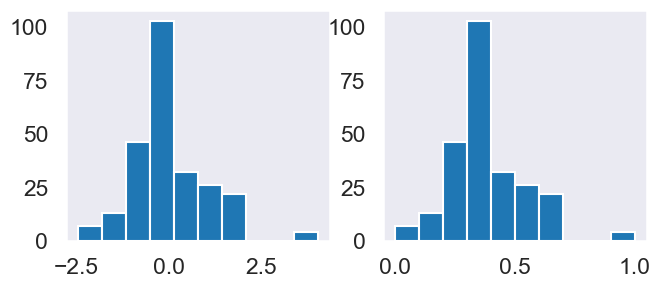

In [21]:
f, ax = plt.subplots(1,2,figsize=(7.5, 3))
ax[0].hist(scalled_st['Mean Log P'])
ax[1].hist(scalled_mm['Mean Log P'])


(array([33., 22., 44., 58., 45., 18., 12., 12.,  7.,  2.]),
 array([-1.7348013 , -1.25098287, -0.76716443, -0.283346  ,  0.20047244,
         0.68429087,  1.16810931,  1.65192774,  2.13574618,  2.61956461,
         3.10338304]),
 <BarContainer object of 10 artists>)

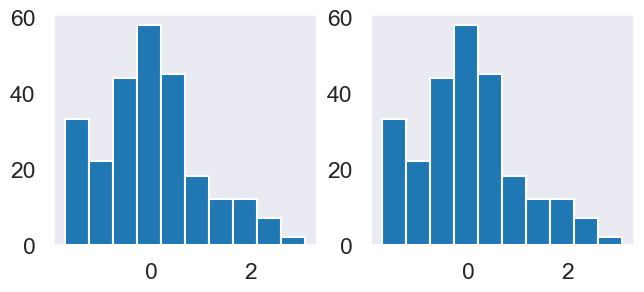

In [22]:
f, ax = plt.subplots(1,2,figsize=(7.5, 3))
ax[0].hist(scalled_st['TPSA'])
ax[1].hist(scalled_st['TPSA'])


(array([66., 63., 61., 25., 15., 10.,  5.,  5.,  2.,  1.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

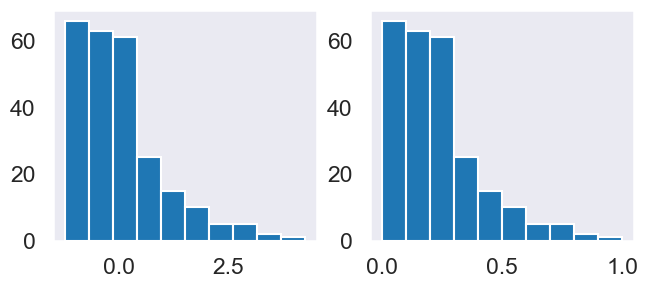

In [23]:
f, ax = plt.subplots(1,2,figsize=(7.5, 3))
ax[0].hist(scalled_st['NumRotatableBonds'])
ax[1].hist(scalled_mm['NumRotatableBonds'])

### loadings

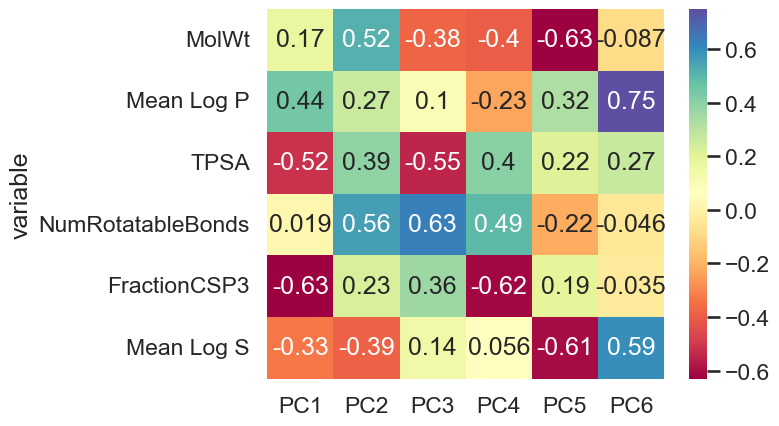

In [24]:
pca_mm = PCA().fit(df_mm)
loadings = pca_mm.components_
num_pc = pca_mm.n_features_in_
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = df_features[features].columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()

### Number of components

In [25]:
pca_mm = PCA().fit(df_mm)
print(np.array_str(pca_mm.explained_variance_, precision=3))
print(np.array_str(pca_mm.explained_variance_ratio_, precision=3))

[0.089 0.07  0.02  0.014 0.003 0.   ]
[0.453 0.357 0.103 0.073 0.013 0.001]


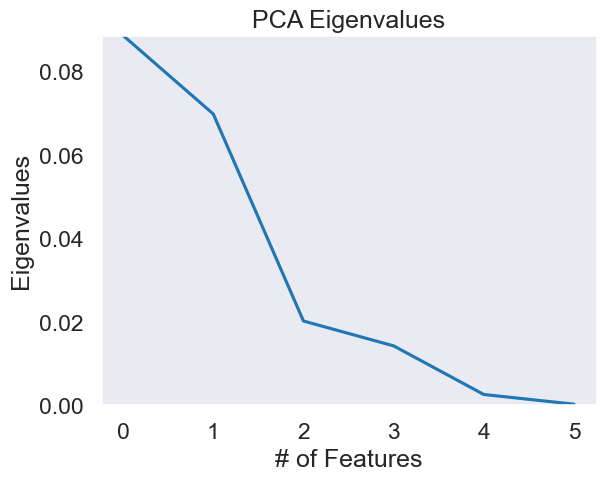

In [26]:
plt.ylabel('Eigenvalues')
plt.xlabel('# of Features')
plt.title('PCA Eigenvalues')
plt.ylim(0,max(pca_mm.explained_variance_))
plt.style.context('seaborn-v0_8-whitegrid')
plt.axhline(y=1, color='r', linestyle='--')
plt.plot(pca_mm.explained_variance_)
plt.show()

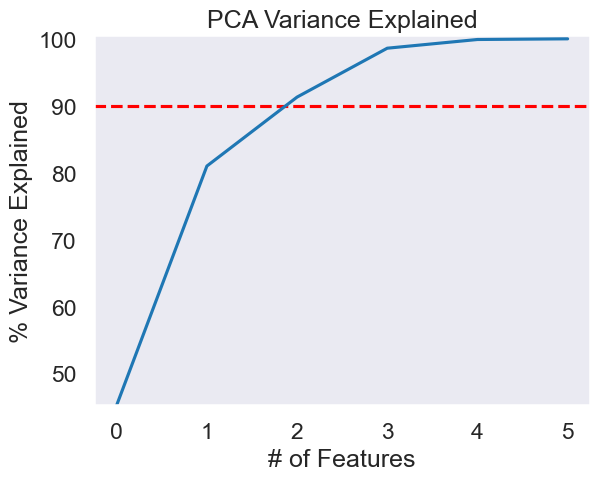

In [27]:
variance = pca_mm.explained_variance_ratio_ #calculate variance ratios
var = np.cumsum(np.round(pca_mm.explained_variance_ratio_,decimals=3)*100)

plt.ylabel('% Variance Explained')
plt.xlabel('# of Features')
plt.title('PCA Variance Explained')
plt.ylim(min(var),100.5)
plt.style.context('seaborn-v0_8-whitegrid')
plt.axhline(y=90, color='r', linestyle='--')
plt.plot(var)
plt.show()

## PCA analysis of reduced dataset with Standard Scaler

.venv/lib/python3.11/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: In a future version, DataFrame.max(axis=None) will return a scalar max over the entire DataFrame. To retain the old behavior, use 'frame.max(axis=0)' or just 'frame.max()'
  return reduction(axis=axis, out=out, **passkwargs)


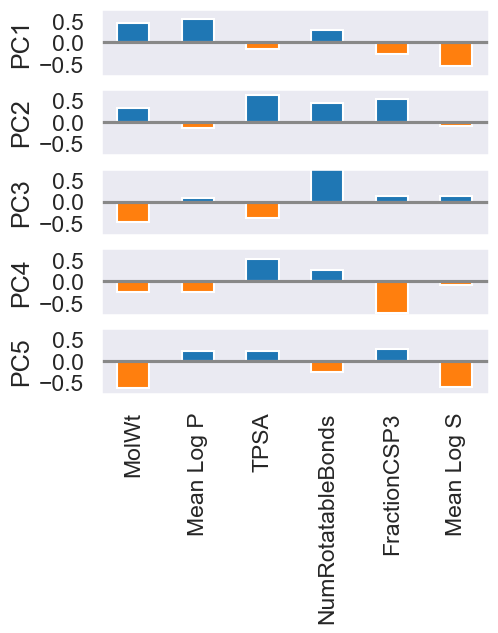

In [28]:
loadings = pd.DataFrame(pca_st.components_[0:5, :], columns=df_features[features].columns)
maxPC = 1.01 * np.max(np.max(np.abs(loadings.loc[0:5, :])))

f, axes = plt.subplots(5, 1, figsize=(5, 5), sharex=True)
for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-maxPC, maxPC)


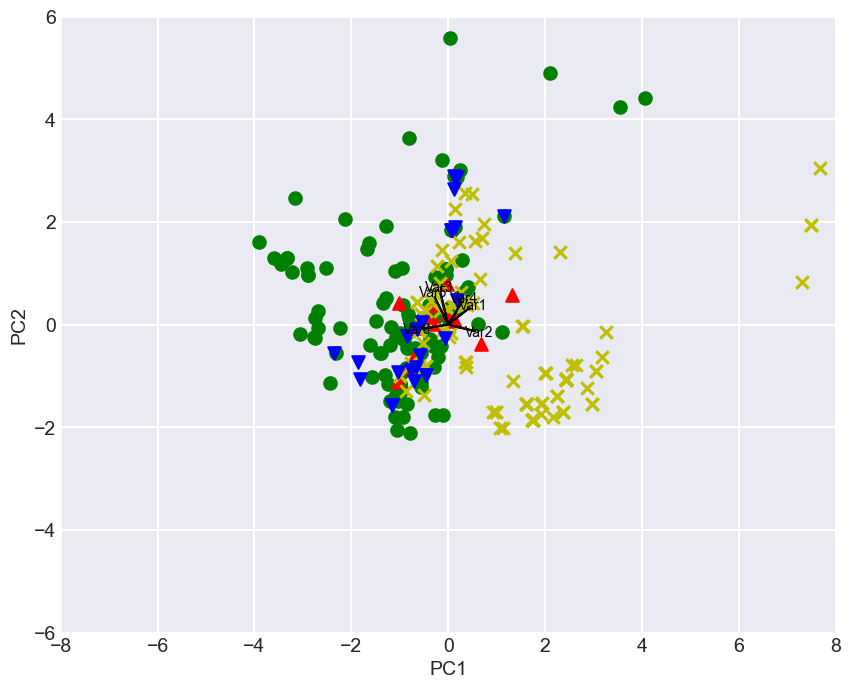

In [29]:
## Biplot withou using bioinformatik

plt.style.use('seaborn-v0_8-dark')
pca = PCA(n_components = 2)
X = pca.fit_transform(df_st) # project the original data into the PCA space
y = df_features['Scaffold']

def biplot(score, coeff , y):
    '''
    Author: Serafeim Loukas, serafeim.loukas@epfl.ch
    Inputs:
       score: the projected data
       coeff: the eigenvectors (PCs)
       y: the class labels
   '''
    xs = score[:,0] # projection on PC1
    ys = score[:,1] # projection on PC2
    n = coeff.shape[0] # number of variables
    plt.figure(figsize=(10,8), dpi=100)
    classes = np.unique(y)
    colors = ['g','r','y', 'b']
    markers=['o','^','x','v']
    for s,l in enumerate(classes):
        plt.scatter(xs[y==l],ys[y==l], c = colors[s], marker=markers[s]) # color based on group
    for i in range(n):
        #plot as arrows the variable scores (each variable has a score for PC1 and one for PC2)
        plt.arrow(0, 0, coeff[i,0], coeff[i,1], color = 'k', alpha = 0.9,linestyle = '-',linewidth = 1.5, overhang=0.2)
        plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, "Var"+str(i+1), color = 'k', ha = 'center', va = 'center',fontsize=10)

    plt.xlabel("PC{}".format(1), size=14)
    plt.ylabel("PC{}".format(2), size=14)
    limx= int(xs.max()) + 1
    limy= int(ys.max()) + 1
    plt.xlim([-limx,limx])
    plt.ylim([-limy,limy])
    plt.grid()
    plt.tick_params(axis='both', which='both', labelsize=14)

# Call the biplot function for only the first 2 PCs
biplot(X[:,0:2], np.transpose(pca.components_[0:2, :]), y)
plt.show()

### loadings plots 

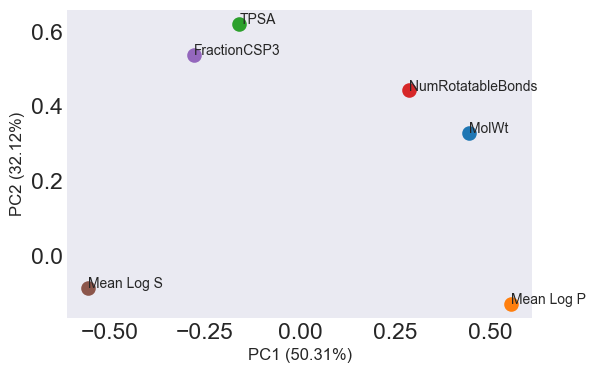

In [30]:
from bioinfokit.visuz import cluster
loadings = pca_st.components_
# get PCA loadings plots (2D)
cluster.pcaplot(x=loadings[0], y=loadings[1], labels=df_features[features].columns.values,
var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
axlabelfontsize= 12,
show=True)

In [31]:
# Save PCA loadings plots (2D)
cluster.pcaplot(x=loadings[0], y=loadings[1], labels=df_features[features].columns.values,
var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
axlabelfontsize= 12,
figtype='svg')

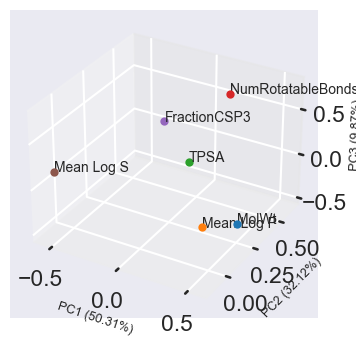

In [32]:
loadings = pca_st.components_
# get PCA loadings plots (2D)
cluster.pcaplot(x=loadings[0], y=loadings[1], z=loadings[2],  labels=df_features[features].columns.values,
    var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
    var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
    var3=round(pca_st.explained_variance_ratio_[2]*100, 2),
    show=True)

### Biplot

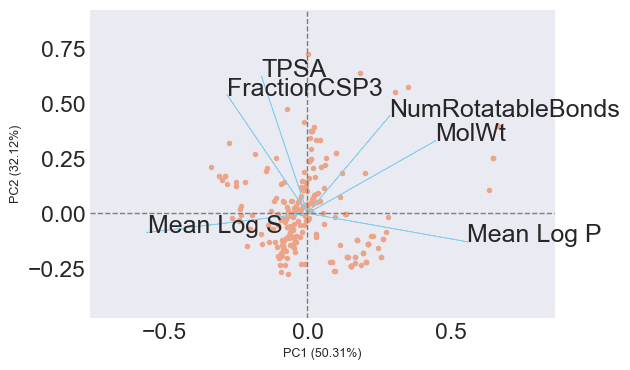

In [33]:
pca_scores = PCA().fit_transform(df_st)
# get 2D biplot
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
show=True)

In [34]:
# Save 2D biplot
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
axlabelfontsize= 12,
figtype='svg')

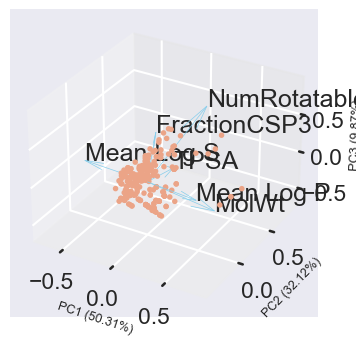

In [35]:
# get 3D biplot
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values, 
    var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
    var2=round(pca_st.explained_variance_ratio_[1]*100, 2), 
    var3=round(pca_st.explained_variance_ratio_[2]*100, 2),
    show=True)

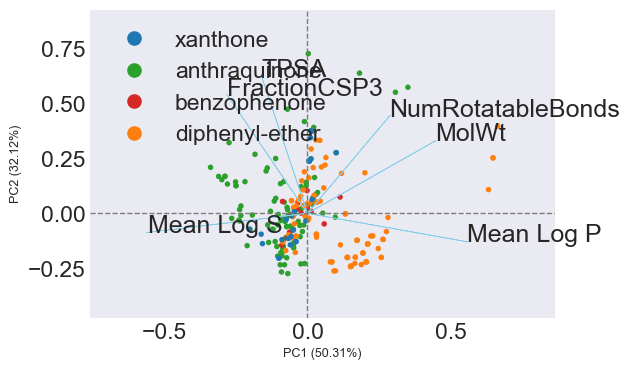

In [36]:
# get 2D biplot
target = df_features['Scaffold'].to_list()
pca_scores = PCA().fit_transform(df_st)

cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
colorlist=target,colordot=['tab:blue','tab:green', 'tab:red', 'tab:orange'],
show=True)

In [37]:
# save biplot labeled
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_st.explained_variance_ratio_[0]*100, 2),
var2=round(pca_st.explained_variance_ratio_[1]*100, 2),
colorlist=target,colordot=['tab:blue','tab:green', 'tab:red', 'tab:orange'],
axlabelfontsize= 12,
figtype='svg')

# PCA with all transformers

### Imports and define functions

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler,QuantileTransformer,RobustScaler,Normalizer,MaxAbsScaler,MinMaxScaler,PowerTransformer

In [39]:
def transformer_bundle(X_train):
    """Takes:
        dataframe containing the features to be transformed
    Returns:
        four dicts:
            {keys: Transformer, values: transformed data}
            {keys: Transformer, values: PCA projection for each observation}
            {keys: Transformer, values: loading for each component}
            {keys: Transformer, values: explained variance ratio for each component}
    """
    transformer_dict = {'StandardScaler': StandardScaler(), 
                        'QuantileTransformer':QuantileTransformer(), 
                        'RobustScaler':RobustScaler(), 
                        'Normalizer':Normalizer(), 
                        'MaxAbsScaler':MaxAbsScaler(), 
                        'MinMaxScaler':MinMaxScaler(), 
                        'PowerTransformer':PowerTransformer()}

    X_train_trans_dict = {trs:transformer_dict[trs].fit_transform(X_train) for trs in transformer_dict.keys()} 
    X_train_trans_dict['NoTransformer'] = X_train.values
    
    X_train_pca_dict = {trs:PCA().fit_transform(X_train_trans_dict[trs]) for trs in transformer_dict.keys()}
    X_train_pca_dict['NoTransformer'] = PCA().fit_transform(X_train)

    X_train_loadings_dict = {trs:PCA().fit(X_train_trans_dict[trs]).components_ for trs in transformer_dict.keys()}
    X_train_loadings_dict['NoTransformer'] = PCA().fit(X_train).components_
    
    X_train_explainedvariance_dict = {trs:PCA().fit(X_train_trans_dict[trs]).explained_variance_ratio_ for trs in transformer_dict.keys()}
    X_train_explainedvariance_dict['NoTransformer'] = PCA().fit(X_train).explained_variance_ratio_

    return X_train_trans_dict, X_train_pca_dict, X_train_loadings_dict , X_train_explainedvariance_dict

In [40]:
def trans_heat_plot(X_trans_dict, axis_labels,save=False):
    """Takes:
        dict with {keys: Transformer, values: transformed data}
        list with labels for y and x axis;
    Optional:
        save plot as svg
    Returns:
        a heatmap for each transformed features
    """
    nrows = len(X_trans_dict.keys())//2
    ncols = 2
    fig,ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*6,nrows*3))
    for i in range(len(X_trans_dict.keys())):
        # the fancy modulo is just to make the "no transformation" come first...
        ind = (i-1)%len(X_trans_dict)
        trs = list(X_trans_dict.keys())[ind]
        X = X_trans_dict[trs]
                   
        this_ax = ax[i//2,i%2]
        covmtrx = (np.cov(X.T))
        mask = np.triu(covmtrx,1)
        sns.heatmap(covmtrx, 
                    square=True,
                    mask = mask,
                    yticklabels=axis_labels,
                    xticklabels=axis_labels,
                    center= 0,
                    cmap=(sns.color_palette('RdBu_r',256)),
                    ax=this_ax,
           )
        this_ax.set_title(trs,loc='left', fontsize='x-large')
        this_ax.set_xticklabels(this_ax.get_xticklabels(), rotation=30)
        
        
    plt.tight_layout()        
    if save==True:
        plt.savefig('heatmap.svg')
    else: 
        plt.show()

In [41]:
def pca_scree_plot(X_explainedvariance_dict, threshold=80, save=False):
    """Takes:
        dict with {keys: Transformer, values: explained variance ratio for each component}
    Optional:
        scalar threshold value to consider meaningfull PCs (red horizontal line)
        save plot as svg
    Returns:
        scree plot for each transformation technique
    """    
    n_components= len(X_explainedvariance_dict[list(X_explainedvariance_dict.keys())[0]]) # get the number the of elements in the first key (number of components)
    pc_list = ["PC"+str(i) for i in list(range(1, n_components+1))] # PC1, PC2 etc

    ncols = 2
    nrows = len(X_explainedvariance_dict.keys())//2

    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*4,nrows*3))
    for i in range(len(X_explainedvariance_dict.keys())):
        # the fancy modulo is just to make the "no transformation" come first...
        ind = (i-1)%len(X_explainedvariance_dict)
        trs = list(X_explainedvariance_dict.keys())[ind]
        # calculates the cumulative sum of explained variance
        var = np.cumsum(np.round(X_explainedvariance_dict[trs],decimals=3)*100) 
        
        this_ax = ax[i//2,i%2]
        sns.lineplot(data=None, x=pc_list, y=var, ax=this_ax).axhline(threshold, color='r', linestyle='--')
           # set axis labels and title
        this_ax.set_xlabel('N.° of components')
        this_ax.set_ylabel('Variance explained (%)')
        this_ax.set_ylim(min(var),100.5)
        this_ax.set_title(trs, loc='left', fontsize='large')
    plt.tight_layout(pad=0.5, )
    if save==True:
        plt.savefig('scree-plots.svg')
    else: 
        plt.show()

In [42]:
def pca_loadings_plot(X_loadings_dict, features_name, X_explainedvariance_dict, colors=None, scale=1, arrow_size=0.05, save=False):
    """Takes:
        dict with {keys: Transformer, values: loading for each component}
        list with the name of the features
        dict with {keys: Transformer, values: explained variance ratio for each component} to label x and y axis with explained variance
    Optional:
        list of colors for the arrows
        scalar to scale the loadings
        scalar with the arrow size
        save plot as svg
    Returns:
        loading plot with arrows for each transformation technique
    """
    nrows = len(X_loadings_dict.keys())//2
    ncols = 2
    pc_list = ["PC"+str(i) for i in list(range(1, len(features_name)+1))]
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*4,nrows*3))
    for i in range(len(X_loadings_dict.keys())):
        # the fancy modulo is just to make the "no transformation" come first...
        ind = (i-1)%len(X_loadings_dict)
        trs = list(X_loadings_dict.keys())[ind]
        coeff = np.vstack((X_loadings_dict[trs][0,:],X_loadings_dict[trs][1,:])).T
        
        this_ax = ax[i//2,i%2]
        for i, label in enumerate(features_name):
            this_ax.arrow(
                0,
                0,
                coeff[i, 0] * scale,
                coeff[i, 1] * scale,
                head_width=arrow_size * scale,
                head_length=arrow_size * scale,
                color="#000" if colors is None else colors[i],
            )
            this_ax.text(
                coeff[i, 0] * 1.15 * scale,
                coeff[i, 1] * 1.15 * scale,
                label,
                color="#000" if colors is None else colors[i],
                ha="center",
                va="center",
            )

           # set axis labels and title
        this_ax.set_xlabel(f"PC1 ({X_explainedvariance_dict[trs][0]*100:.2f} %)")
        this_ax.set_ylabel(f"PC2 ({X_explainedvariance_dict[trs][1]*100:.2f} %)")
        this_ax.set_title(trs, loc='left', fontsize='large')
    plt.tight_layout(pad=0.5, )
    if save==True:
        plt.savefig('loadings-plots.svg')
    else: 
        plt.show()

In [43]:
def pca_scatter_plot(X_pca_dict, y, y_order=None, explained_variance_dict=None, save=False):
    """Takes:
        dict with {keys: Transformer, values: PCA projection for each observation}
        Series with labels for coloring the scatter points,
    Optional:
        list with order of coloring labels
        dict with {keys: Transformer, values: explained variance ratio for each component} to label x and y axis with explained variance
        save plot as svg
    Returns:
        scatter plot for each transformation technique
    """
    customer_palette = sns.color_palette('deep', len(y.unique()))
    y = np.array(y)
    nrows = len(X_pca_dict.keys())//2
    ncols = 2

    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*4,nrows*3))
    for i in range(len(X_pca_dict.keys())):
        # the fancy modulo is just to make the "no transformation" come first...
        ind = (i-1)%len(X_pca_dict)
        trs = list(X_pca_dict.keys())[ind]
        X = X_pca_dict[trs]
        
        this_ax = ax[i//2,i%2]
        sns.scatterplot(data=None, x=X[:,0], y=X[:,1], 
                            hue=y, hue_order=y_order, 
                            alpha=0.6, palette=customer_palette, ax=this_ax)
           # set axis labels and title
        this_ax.set_title(trs, loc='left', fontsize='large')
        if explained_variance_dict is not None:
            this_ax.set_xlabel(f"PC1 ({explained_variance_dict[trs][0]*100:.2f} %)")
            this_ax.set_ylabel(f"PC2 ({explained_variance_dict[trs][1]*100:.2f} %)")
        else:
            this_ax.set_xlabel(f"PC1")
            this_ax.set_ylabel(f"PC2")
        if this_ax ==[0,1]:
            this_ax.legend(bbox_to_anchor=(1.01, 1.0), loc='upper left')
        else:
            this_ax.get_legend().remove()
    plt.tight_layout(pad=0.5, )
    if save==True:
        plt.savefig('pca-scatter-plots.svg')
    else: 
        plt.show()

### Effect of transformers in the dataset

In [44]:
X_train = df_features[features].copy() # dataframe containing the molecular descriptors
X_train.columns = ['MW', 'LogP', 'TPSA', 'RB', 'FCsp3','LogS'] # rename columns for readability

y_train = df_features['Scaffold'].copy() # Scaffold is used as label to color PCA projection


In [45]:
# X_trans_dict -> For each transformer, the transformed dataset
# X_pca_dict -> For each transformer the PCA projection of each data point
# X_loadings_dict -> For each transformer, the loadings for all PCs
# X_explainedvariance_dict -> For each transformer, the explained variance for all PCs

X_trans_dict, X_pca_dict , X_loadings_dict , X_explainedvariance_dict = transformer_bundle(X_train)

.venv/lib/python3.11/site-packages/sklearn/preprocessing/_data.py:2627: UserWarning: n_quantiles (1000) is greater than the total number of samples (253). n_quantiles is set to n_samples.
  warnings.warn(


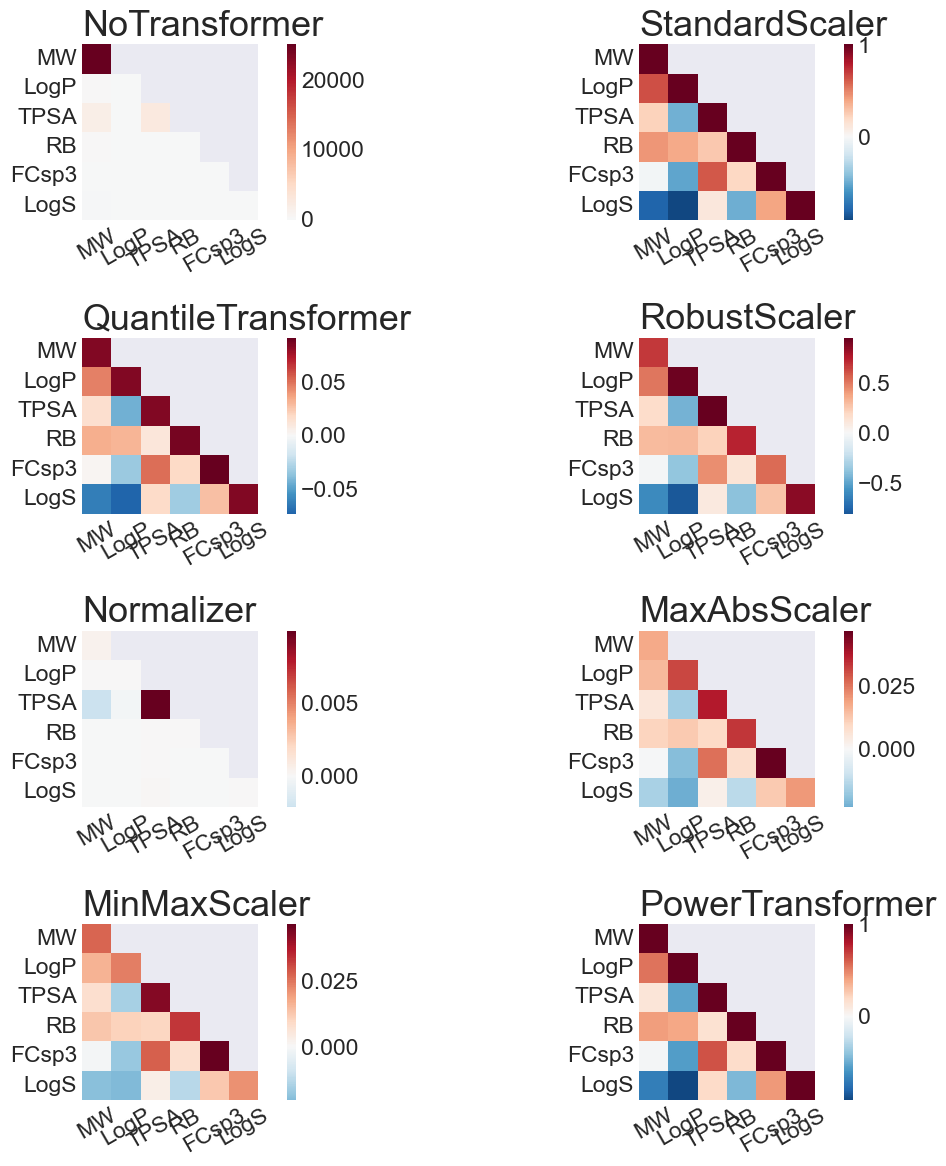

In [46]:
trans_heat_plot(X_trans_dict, axis_labels=X_train.columns,save=True)

### PCA with different transformers

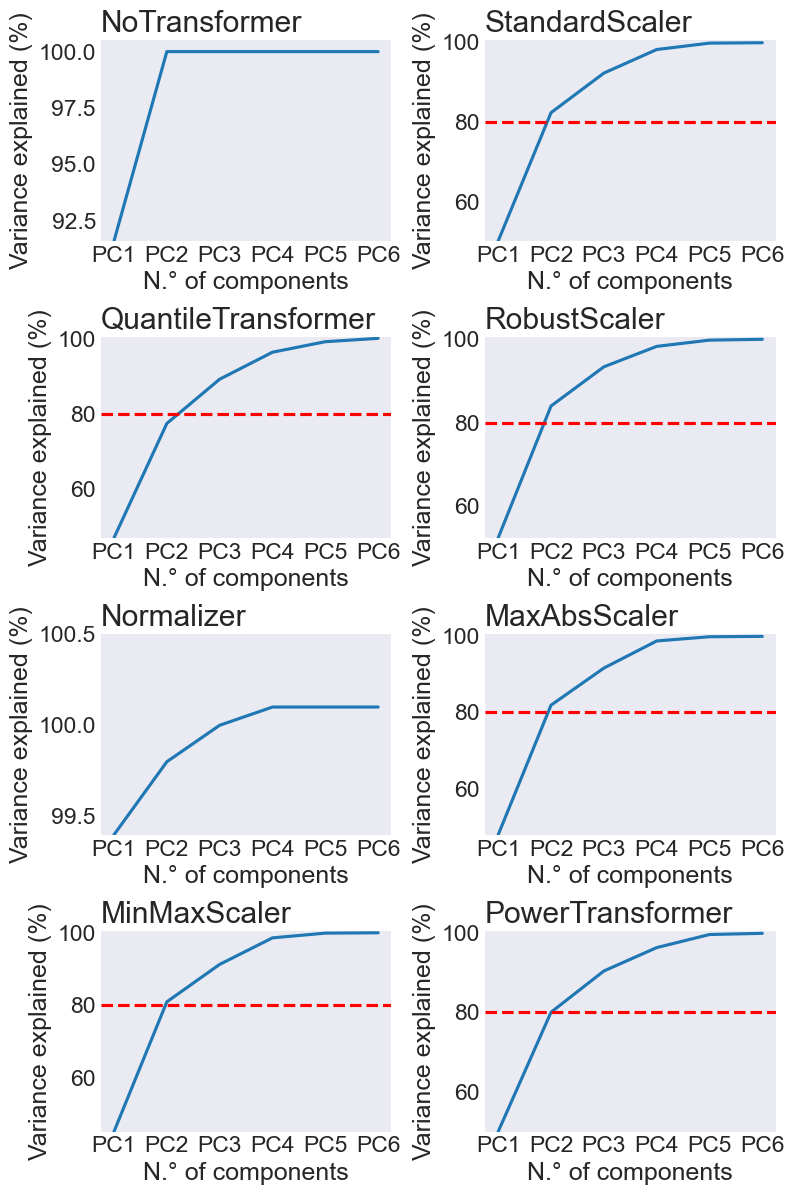

In [47]:
pca_scree_plot(X_explainedvariance_dict,save=True)

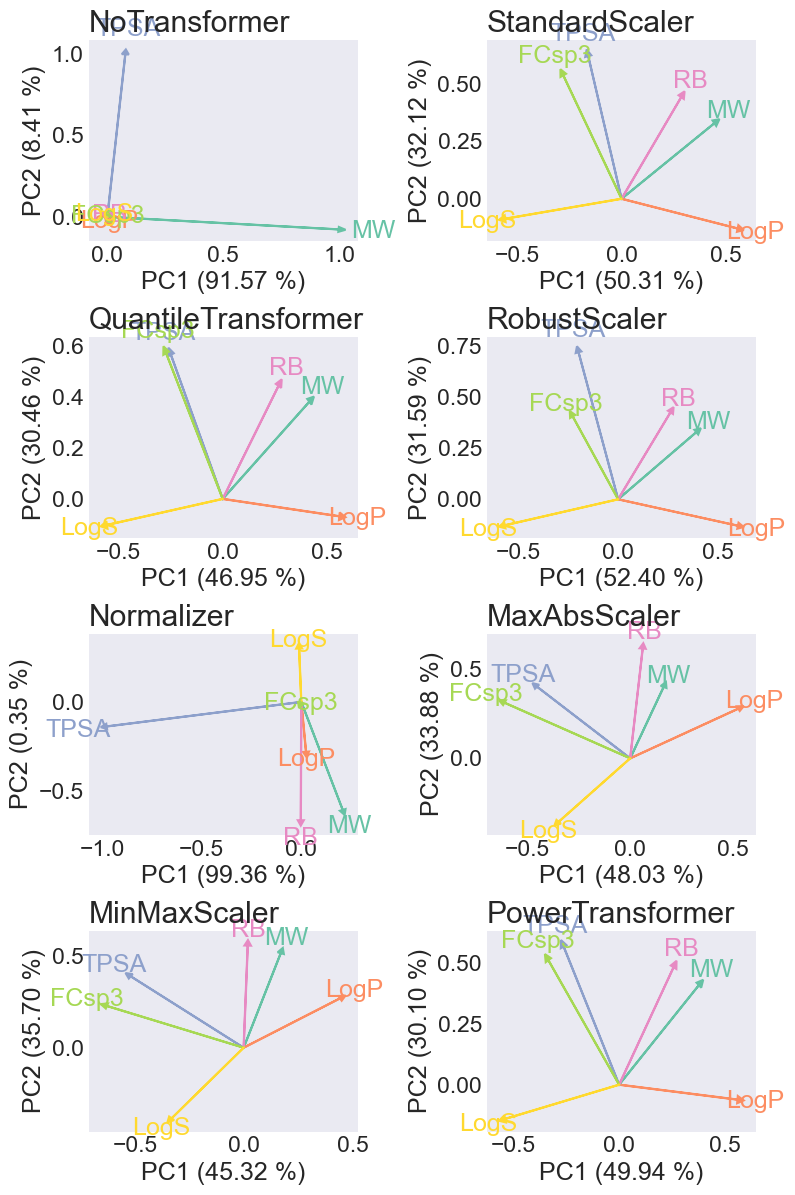

In [48]:
pca_loadings_plot(X_loadings_dict, X_train.columns, X_explainedvariance_dict, scale=1, colors=sns.color_palette('Set2', 6), arrow_size=0.03)

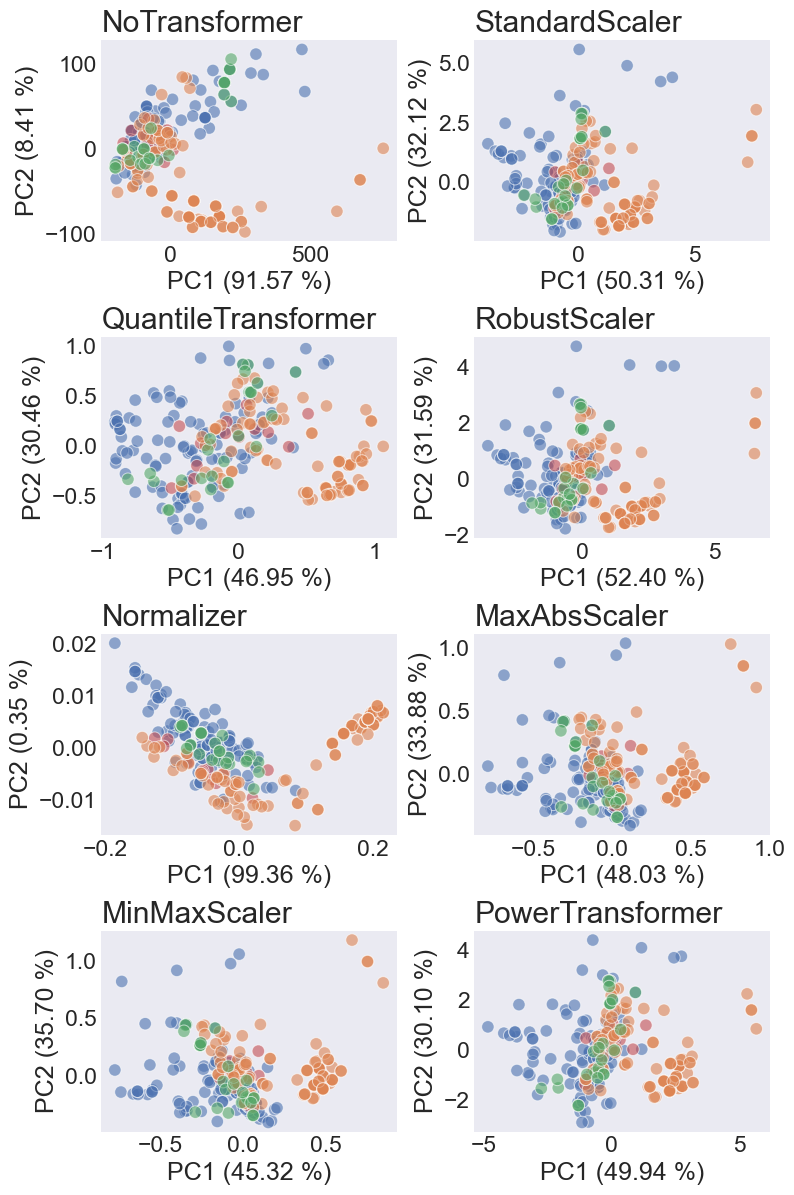

In [49]:
pca_scatter_plot(X_pca_dict, y_train ,y_order=['anthraquinone','diphenyl-ether','xanthone','benzophenone'], explained_variance_dict=X_explainedvariance_dict,save=True)

## PCA analysis of reduced dataset with RobustScaler

In [50]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler

In [51]:
df_rs =  RobustScaler().fit_transform(df_features[features])
print(df_features[features].head(5))
print(pd.DataFrame(df_rs, columns=df_features[features].columns).head(5))

     MolWt  Mean Log P    TPSA  NumRotatableBonds  FractionCSP3  Mean Log S
0  754.785    6.313150  217.35               14.0      0.333333      -10.98
1  726.731    5.433450  239.35               12.0      0.300000      -11.22
2  386.400    2.995367  124.29                6.0      0.333333       -5.51
3  372.373    2.581350  135.29                5.0      0.300000       -5.63
4  354.358    3.091300  115.06                4.0      0.200000       -5.81
      MolWt  Mean Log P      TPSA  NumRotatableBonds  FractionCSP3  Mean Log S
0  1.924994    1.805919  2.263624           4.000000          0.64   -2.715909
1  1.779985    1.359635  2.696439           3.333333          0.48   -2.825000
2  0.020841    0.122761  0.432815           1.333333          0.64   -0.229545
3 -0.051663   -0.087275  0.649223           1.000000          0.48   -0.284091
4 -0.144781    0.171430  0.251230           0.666667          0.00   -0.365909


(array([  7.,  13.,  46., 103.,  32.,  26.,  22.,   0.,   0.,   4.]),
 array([-2.17393253, -1.5509064 , -0.92788027, -0.30485415,  0.31817198,
         0.94119811,  1.56422423,  2.18725036,  2.81027649,  3.43330261,
         4.05632874]),
 <BarContainer object of 10 artists>)

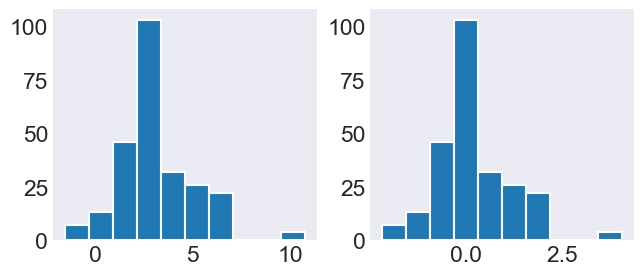

In [52]:
f, ax = plt.subplots(1,2,figsize=(7.5, 3))
ax[0].hist(df_features['Mean Log P'])
ax[1].hist(df_rs[:,1])

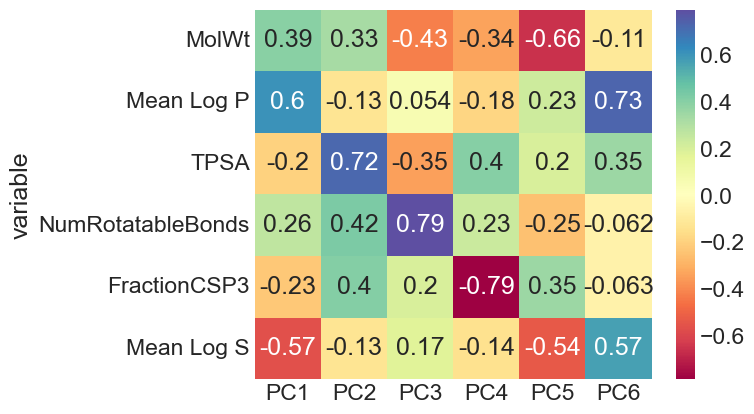

In [53]:
pca_rs = PCA().fit(df_rs)
loadings = pca_rs.components_
num_pc = pca_rs.n_features_in_
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = df_features[features].columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()

### Number of components

In [54]:
print(np.array_str(pca_rs.explained_variance_, precision=3))
print(np.array_str(pca_rs.explained_variance_ratio_, precision=3))

[2.44  1.471 0.436 0.23  0.071 0.008]
[0.524 0.316 0.094 0.049 0.015 0.002]


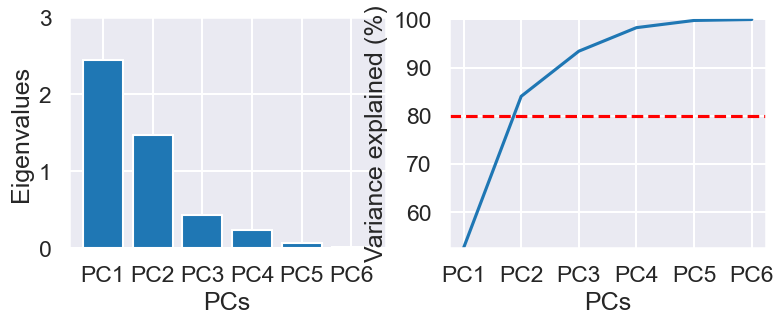

In [55]:
variance = pca_rs.explained_variance_ratio_ #calculate variance ratios
var = np.cumsum(np.round(pca_rs.explained_variance_ratio_,decimals=3)*100)

sns.set_style('darkgrid')
sns.set_context("talk")
f, ax = plt.subplots(1,2,figsize=(9, 3))

ax[0].set(xlabel='PCs', ylabel='Eigenvalues',
    ylim = [0,max(pca_rs.explained_variance_)],yticks=[0,1,2,3])
#ax[0].axhline(y=1, color='r', linestyle='--')
ax[0].bar(x=pc_list, height=pca_rs.explained_variance_)

ax[1].set(xlabel='PCs', ylabel='Variance explained (%)', ylim = [min(var),100.5])
ax[1].axhline(y=80, color='r', linestyle='--')
ax[1].plot(pc_list,var)

plt.savefig('plots/subplot_scree-plot-rs.svg')

### PCA analysis

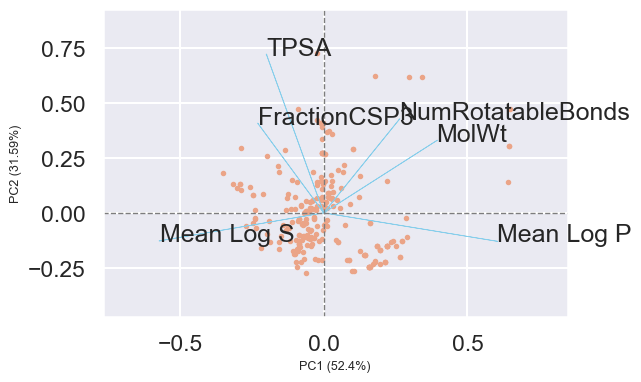

In [56]:
from bioinfokit.visuz import cluster
pca_scores = PCA().fit_transform(df_rs)
loadings = pca_rs.components_

# get 2D biplot
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_rs.explained_variance_ratio_[0]*100, 2),
var2=round(pca_rs.explained_variance_ratio_[1]*100, 2),
show=True)

In [57]:
# Save 2D biplot
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_rs.explained_variance_ratio_[0]*100, 2),
var2=round(pca_rs.explained_variance_ratio_[1]*100, 2),
axlabelfontsize= 12,
figtype='svg')

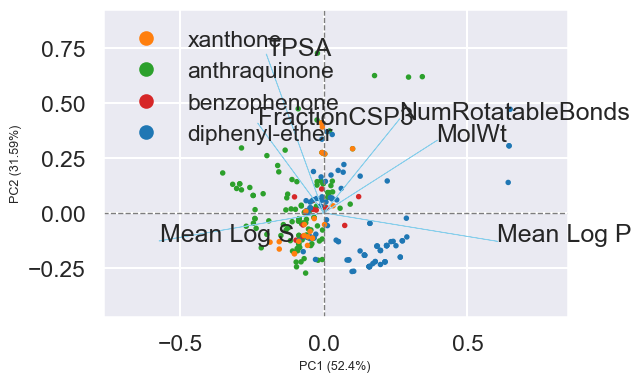

In [58]:
# get 2D biplot
target = df_features['Scaffold'].to_list()

cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_rs.explained_variance_ratio_[0]*100, 2),
var2=round(pca_rs.explained_variance_ratio_[1]*100, 2),
colorlist=target,colordot=['tab:orange','tab:green', 'tab:red', 'tab:blue'],
show=True)

In [59]:
# save biplot labeled
cluster.biplot(cscore=pca_scores, loadings=loadings, labels=df_features[features].columns.values,
var1=round(pca_rs.explained_variance_ratio_[0]*100, 2),
var2=round(pca_rs.explained_variance_ratio_[1]*100, 2),
colorlist=target,colordot=['tab:orange','tab:green', 'tab:red', 'tab:blue'],
figtype='svg')